# Compute Liveability for Each Suburb

## Imports
Libraries used to aggregate the data and log-transform the distances.

In [1]:
import numpy as np
import pandas as pd

### Read in Final Parquet Data

In [5]:
df = pd.read_parquet("../rea_data/analysis/rental_data_development/rentals.parquet")
df.shape

(12316, 77)

In [24]:
list(df.columns)

['lat',
 'lon',
 'listing_id',
 'suburb',
 'weekly_rent',
 'date_listed',
 'bedrooms',
 'bathrooms',
 'carspaces',
 'property_type',
 'feat_built_in_wardrobes',
 'feat_heating',
 'feat_dishwasher',
 'feat_secure_parking',
 'feat_internal_laundry',
 'feat_air_conditioning',
 'feat_balcony___deck',
 'feat_gas',
 'feat_floorboards',
 'feat_bath',
 'feat_intercom',
 'feat_ensuite',
 'feat_fully_fenced',
 'feat_study',
 'feat_furnished',
 'feat_split_system_air_conditioning',
 'feat_pets_allowed',
 'feat_close_to_shops',
 'feat_split_system_heating',
 'feat_close_to_transport',
 'feat_close_to_schools',
 'feat_remote_garage',
 'feat_shed',
 'feat_ducted_heating',
 'feat_garden___courtyard',
 'feat_gym',
 'feat_outdoor_entertainment_area',
 'feat_balcony',
 'feat_broadband_internet_access',
 'feat_alarm_system',
 'feat_swimming_pool',
 'feat_courtyard',
 'feat_solar_panels',
 'feat_fireplaces',
 'feat_pool_spa_count_0',
 'feat_bathtub',
 'feat_ensuites',
 'feat_carpeted',
 'feat_gas_applianc

## Standardised log median distance by suburb
Given a distance column, this function:
1. Takes the median distance for each suburb.
2. Applies log10 to the medians (non-positive medians become NaN, since log10 is undefined there).
3. Standard scales the log medians to mean 0 and s² = 1 (sample variance, `ddof=1`).
4. Returns a DataFrame with one row per suburb and its standardised log median distance.

In [25]:
def standardised_log_median_by_suburb(
    df: pd.DataFrame,
    distance_column: str,
    suburb_column: str = "suburb",
) -> pd.DataFrame:
    
    """Return each suburb's standardised log10 median distance.

    Higher values mean the suburb is further away than average.
    """
    # Median distance for each suburb (NaN distances are skipped)
    median_distances = df.groupby(suburb_column)[distance_column].median()

    # Mask non-positive medians so log10 gives NaN instead of -inf
    log_median_distances = np.log10(median_distances)

    mean_log_distance = log_median_distances.mean()
    std_log_distance = log_median_distances.std(ddof=1)

    # Standard scale: mean 0, sample variance 1
    standardised_log_distances = (
        log_median_distances - mean_log_distance
    ) / std_log_distance

    return standardised_log_distances.rename(
        f"{distance_column}_standardised_log_median"
    ).reset_index()

## Education score
Education score is the average of each suburb's standardised log median distance to a primary school and to a secondary school. Both are computed with `standardised_log_median_by_suburb`, merged on suburb, then averaged. Suburbs missing either value get NaN rather than a score based on one school type.

In [26]:
primary_column = "school_primary_road_distance_m"
secondary_column = "school_secondary_road_distance_m"  # adjust if named differently

primary_standardised = standardised_log_median_by_suburb(df, primary_column)
secondary_standardised = standardised_log_median_by_suburb(df, secondary_column)

education_scores = primary_standardised.merge(
    secondary_standardised, on="suburb", how="outer"
)

# Average the two standardised values (NaN if either is missing)
education_scores["education_score"] = education_scores[
    [
        f"{primary_column}_standardised_log_median",
        f"{secondary_column}_standardised_log_median",
    ]
].mean(axis=1, skipna=False)

education_scores.head()

,suburb,school_primary_road_distance_m_standardised_log_median,school_secondary_road_distance_m_standardised_log_median,education_score
0,ABBOTSFORD,-0.743658,-1.008942,-0.876300
1,ABERFELDIE,-0.654586,-1.654268,-1.154427
2,AIRPORT WEST,-0.351815,-0.165404,-0.258610
3,ALBANVALE,-0.748711,-0.025797,-0.387254
4,ALBERT PARK,-1.110940,-0.788401,-0.949670


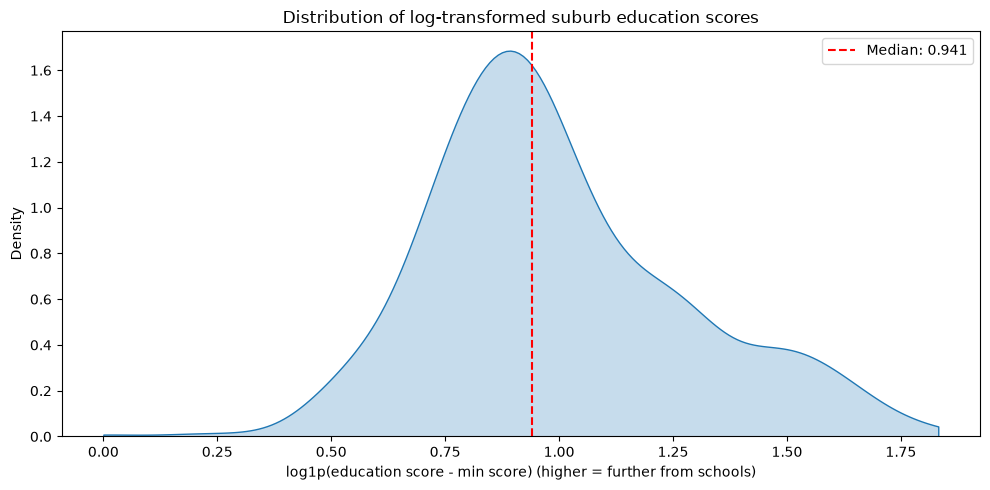

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Drop suburbs with no education score (missing primary or secondary value)
valid_education_scores = education_scores["education_score"].dropna()

# Shift so the minimum is 0, making every value valid for log1p
shifted_education_scores = valid_education_scores - valid_education_scores.min()
log_education_scores = np.log1p(shifted_education_scores)
median_log_education_score = log_education_scores.median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(log_education_scores, fill=True, cut=0, ax=ax)

# Dashed line marking the median suburb
ax.axvline(
    median_log_education_score,
    color="red",
    linestyle="--",
    label=f"Median: {median_log_education_score:.3f}",
)

ax.set_xlabel("log1p(education score - min score) (higher = further from schools)")
ax.set_ylabel("Density")
ax.set_title("Distribution of log-transformed suburb education scores")
ax.legend()
plt.tight_layout()
plt.show()

s^2 of standardised education scores: 1.0000


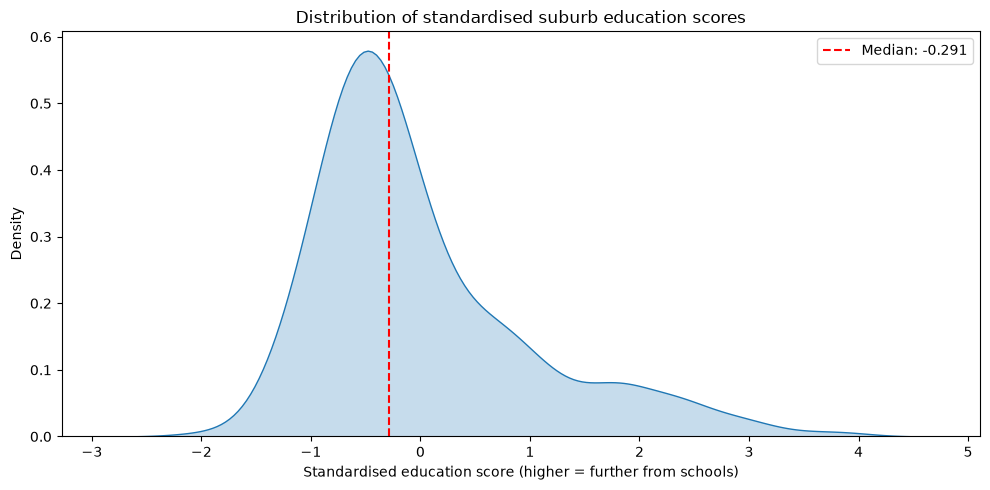

In [31]:
education_score_mean = education_scores["education_score"].mean()
education_score_std = education_scores["education_score"].std(ddof=1)

if education_score_std == 0:
    raise ValueError("All education scores are identical; cannot standardise.")

# Standard scale: mean 0, sample variance 1 (NaNs are preserved)
education_scores["education_score_standardised"] = (
    education_scores["education_score"] - education_score_mean
) / education_score_std

valid_standardised_education_scores = education_scores[
    "education_score_standardised"
].dropna()
median_standardised_education_score = (
    valid_standardised_education_scores.median()
)

print(
    "s^2 of standardised education scores: "
    f"{valid_standardised_education_scores.var(ddof=1):.4f}"
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(valid_standardised_education_scores, fill=True, ax=ax)

# Dashed line marking the median suburb
ax.axvline(
    median_standardised_education_score,
    color="red",
    linestyle="--",
    label=f"Median: {median_standardised_education_score:.3f}",
)

ax.set_xlabel("Standardised education score (higher = further from schools)")
ax.set_ylabel("Density")
ax.set_title("Distribution of standardised suburb education scores")
ax.legend()
plt.tight_layout()
plt.show()

## Healthcare score
Healthcare score is a weighted average of each suburb's standardised log median distance to a hospital (65%) and to a medical centre (35%). Both use `standardised_log_median_by_suburb`, are merged on suburb, then combined. Suburbs missing either value get NaN.

In [28]:
hospital_column = "hospital_road_distance_m"  # adjust if named differently
medical_centre_column = "medical_centre_road_distance_m"  # adjust if needed

hospital_weight = 0.65
medical_centre_weight = 0.35

hospital_standardised = standardised_log_median_by_suburb(df, hospital_column)
medical_centre_standardised = standardised_log_median_by_suburb(
    df, medical_centre_column
)

healthcare_scores = hospital_standardised.merge(
    medical_centre_standardised, on="suburb", how="outer"
)

hospital_standardised_column = f"{hospital_column}_standardised_log_median"
medical_centre_standardised_column = (
    f"{medical_centre_column}_standardised_log_median"
)

# Weighted sum propagates NaN if either component is missing
healthcare_scores["healthcare_score"] = (
    hospital_weight * healthcare_scores[hospital_standardised_column]
    + medical_centre_weight * healthcare_scores[medical_centre_standardised_column]
)

healthcare_scores.sort_values("healthcare_score").reset_index(drop=True)

KeyError: 'Column not found: medical_centre_road_distance_m'